# Database test notebook

Checks `market_data.duckdb` and shows what's in it. **Read-only**: nothing here writes to the database.

**How to use:** pick the project's `.venv` as the kernel, then *Run All*. Every check lands in one PASS / WARN / FAIL table at the end (section 9).

**Before running `refresh.py`:** run the last cell (or restart the kernel). DuckDB allows one writer *or* readers, so an open notebook blocks the refresh.

| Section | What it checks |
|---|---|
| 1 | Files, schema version, row counts |
| 2 | Last refresh runs and errors |
| 3 | Coverage: first / last date of every series |
| 4 | Integrity: keys, dates, ranges, freshness |
| 5 | The as-of rule (no look-ahead) |
| 6 | Market data charts |
| 7 | Options implied vol (Bloomberg) and data glitches |
| 8 | Features |
| 9 | Summary of all checks |

In [1]:
# --- Setup -------------------------------------------------------------------
import sys
from pathlib import Path
from datetime import date

ROOT = Path.cwd()
while not (ROOT / "Data" / "DataBase" / "access.py").exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("Open this notebook from inside the repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

from Data.DataBase import access
from Data.DataBase.access import (get_series, get_prices, get_features, get_dividends,
                                  get_option_iv, list_series, list_features)
from Data.DataBase.db import market_db_path, trading_db_path

con = access._market()          # the same read-only connection access.py uses
q = lambda sql, *p: con.execute(sql, list(p)).df()
TODAY = pd.Timestamp(date.today())

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)

# Chart style: thin lines, light grid, fixed colour order (blue, orange, aqua, yellow)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.edgecolor": "#9a9a9a", "axes.labelcolor": "#444", "xtick.color": "#555", "ytick.color": "#555",
    "lines.linewidth": 1.4, "legend.frameon": False, "axes.titleweight": "bold", "axes.titlesize": 11,
})

# Every check calls this; section 9 prints the table.
RESULTS = []
def check(section, name, status, detail=""):
    """status: True -> PASS, False -> FAIL, or the string 'WARN'."""
    s = status if isinstance(status, str) else ("PASS" if bool(status) else "FAIL")
    RESULTS.append({"section": section, "check": name, "result": s, "detail": detail})
    print(f"[{s:4}] {name}" + (f"  ({detail})" if detail else ""))

def lines(df, title, ylabel="", hline=None, logy=False, ax=None):
    ax = ax or plt.subplots()[1]
    for c in df.columns:
        ax.plot(df.index, df[c], label=c)
    if hline is not None:
        ax.axhline(hline, color="#777", lw=0.9, ls="--")
    if logy:
        ax.set_yscale("log")
    ax.set_title(title); ax.set_ylabel(ylabel)
    if len(df.columns) > 1:
        ax.legend(loc="upper left", ncols=len(df.columns))
    return ax

print("Repo:", ROOT)
print("Database:", market_db_path())

Repo: c:\Users\agand\Desktop\Wilfrid Laurier\2026F\LTG project
Database: C:\Users\agand\Desktop\Wilfrid Laurier\2026F\LTG project\Data\DataBase\market_data.duckdb


## 1. Files, schema version, row counts

In [3]:
for p in (market_db_path(), trading_db_path()):
    print(f"{p.name:20} {'exists' if p.exists() else 'MISSING':8} {p.stat().st_size/1e6:7.1f} MB" if p.exists() else f"{p.name} MISSING")
display(q("SELECT * FROM meta.schema_version"))

tables = q("""SELECT table_schema || '.' || table_name AS name, table_type
              FROM information_schema.tables ORDER BY table_schema, table_name""")
tables["rows"] = [con.execute(f"SELECT count(*) FROM {n}").fetchone()[0] for n in tables["name"]]
display(tables)

check(1, "market_data.duckdb exists", market_db_path().exists())
check(1, "schema version recorded", len(q("SELECT * FROM meta.schema_version")) == 1)
expected = {"raw.series", "raw.prices", "raw.corporate_actions", "raw.option_iv", "features.series", "meta.series"}
empty = [n for n, r in zip(tables["name"], tables["rows"]) if n in expected and r == 0]
check(1, "core tables have rows", not empty, f"empty: {empty}" if empty else "")

market_data.duckdb   exists      79.7 MB
trading.duckdb       exists       0.8 MB


,db_name,schema_version,duckdb_version,created_at
0,market_data,1,1.5.6,2026-11-12 07:36:09.079380


,name,table_type,rows
0,clean.corporate_actions,VIEW,1091
1,clean.option_iv,VIEW,505194
2,clean.option_quotes,VIEW,0
3,clean.prices,VIEW,93676
4,clean.series,VIEW,140208
5,features.series,BASE TABLE,110533
6,meta.features,BASE TABLE,15
7,meta.refresh_log,BASE TABLE,91
8,meta.schema_version,BASE TABLE,1
9,meta.series,BASE TABLE,29


[PASS] market_data.duckdb exists
[PASS] schema version recorded
[PASS] core tables have rows


## 2. Refresh runs
One row per source per `refresh.py` run, from `meta.refresh_log`. A source that crashed as a whole (e.g. missing API key) prints `FAILED` in the terminal but has no rows here.

In [4]:
runs = q("""
    SELECT refresh_id, source, count(*) AS series, sum(rows_written) AS rows_written,
           sum((status = 'error')::INT) AS errors, min(started_at) AS started,
           round(epoch(max(finished_at) - min(started_at)), 1) AS seconds
    FROM meta.refresh_log GROUP BY ALL ORDER BY started""")
display(runs)

errs = q("SELECT refresh_id, source, series_id, message FROM meta.refresh_log WHERE status <> 'ok'")
if len(errs): display(errs)
last = runs["refresh_id"].iloc[-1]
check(2, "latest refresh has 0 errors", int(runs.loc[runs.refresh_id == last, "errors"].sum()) == 0, last)
check(2, "every source has run at least once",
      set(runs["source"]) >= {"fred", "cboe", "yfinance", "bloomberg", "features"}, ", ".join(sorted(set(runs["source"]))))

,refresh_id,source,series,rows_written,errors,started,seconds
0,20261112-074159-42fbda,cboe,8,44973.0,0.0,2026-11-12 07:41:59.040641,6.9
1,20261112-074159-42fbda,yfinance,12,94767.0,0.0,2026-11-12 07:42:05.961651,17.5
2,20261112-074159-42fbda,bloomberg,7,518872.0,0.0,2026-11-12 07:42:23.502147,8.1
3,20261112-074159-42fbda,features,15,97660.0,0.0,2026-11-12 07:42:31.737751,1.8
4,20261112-074259-df458d,fred,7,81557.0,0.0,2026-11-12 07:42:59.751227,9.2
5,20261112-074259-df458d,cboe,8,0.0,0.0,2026-11-12 07:43:08.907910,6.4
6,20261112-074259-df458d,yfinance,12,0.0,0.0,2026-11-12 07:43:15.334278,16.5
7,20261112-074259-df458d,bloomberg,7,0.0,0.0,2026-11-12 07:43:31.886028,3.5
8,20261112-074259-df458d,features,15,12873.0,0.0,2026-11-12 07:43:35.473633,1.8


[PASS] latest refresh has 0 errors  (20261112-074259-df458d)
[PASS] every source has run at least once  (bloomberg, cboe, features, fred, yfinance)


## 3. Coverage
First and last date of every series in the catalogue. `stale_days` = business days since the last value (FRED is normally 1–3 behind; WTI and USD/CAD can lag a few more).

,source,series_id,source_code,units,publish_lag_days,first_date,last_date,years,stale_days
0,yfinance,dbc,DBC,USD,0,2006-02-06,2026-11-11,20.8,1
1,yfinance,gld,GLD,USD,0,2004-11-18,2026-11-11,22.0,1
2,yfinance,hyg,HYG,USD,0,2007-04-11,2026-11-11,19.6,1
3,yfinance,ief,IEF,USD,0,2002-07-30,2026-11-11,24.3,1
4,yfinance,move,^MOVE,index points,0,2002-11-12,2026-11-10,24.0,2
5,yfinance,ndx,^NDX,index points,0,1985-10-01,2026-11-11,41.1,1
6,yfinance,qqq,QQQ,USD,0,1999-03-10,2026-11-11,27.7,1
7,yfinance,spx,^GSPC,index points,0,1927-12-30,2026-11-11,98.9,1
8,yfinance,spy,SPY,USD,0,1993-01-29,2026-11-11,33.8,1
9,yfinance,tlt,TLT,USD,0,2002-07-30,2026-11-11,24.3,1


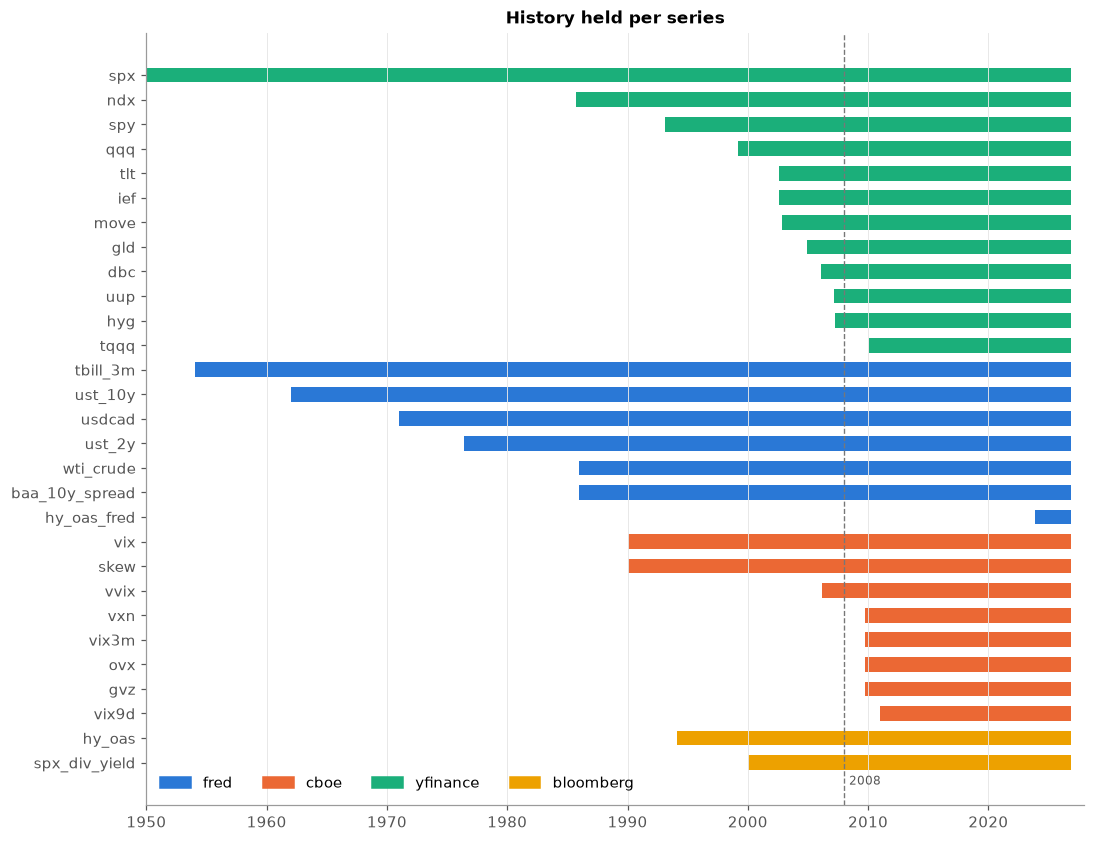

[PASS] every catalogue series has data  (29 series)
[PASS] nothing more than 7 business days old
[WARN] CBOE vol indices start before 2008  (start 2009+: ['gvz', 'ovx', 'vix3m', 'vix9d', 'vxn'] (CBOE's CSVs are cut; older history needs Bloomberg))


In [5]:
cat = list_series()
cat["first_date"] = pd.to_datetime(cat["first_date"]); cat["last_date"] = pd.to_datetime(cat["last_date"])
cat["years"] = ((cat["last_date"] - cat["first_date"]).dt.days / 365.25).round(1)
cat["stale_days"] = [np.busday_count(d.date(), TODAY.date()) if pd.notna(d) else None for d in cat["last_date"]]
display(cat[["source", "series_id", "source_code", "units", "publish_lag_days", "first_date", "last_date", "years", "stale_days"]])

src_color = {"fred": COLORS[0], "cboe": COLORS[1], "yfinance": COLORS[2], "bloomberg": COLORS[3]}
c2 = cat.dropna(subset=["first_date"]).sort_values(["source", "first_date"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(11, 0.28 * len(c2) + 1))
ax.barh(c2["series_id"], mdates.date2num(c2["last_date"]) - mdates.date2num(c2["first_date"]),
        left=mdates.date2num(c2["first_date"]), color=[src_color[s] for s in c2["source"]], height=0.6)
ax.xaxis_date(); ax.set_xlim(mdates.date2num(pd.Timestamp("1950-01-01")), mdates.date2num(TODAY) + 400)
ax.axvline(mdates.date2num(pd.Timestamp("2008-01-01")), color="#777", ls="--", lw=0.9)
ax.text(mdates.date2num(pd.Timestamp("2008-06-01")), -0.9, "2008", color="#555", fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=s) for s, col in src_color.items()], loc="lower left", ncols=4)
ax.set_title("History held per series")
ax.grid(axis="y", visible=False); plt.show()

missing = cat.loc[cat["first_date"].isna(), "series_id"].tolist()
check(3, "every catalogue series has data", not missing, f"missing: {missing}" if missing else f"{len(cat)} series")
stale = cat.loc[cat["stale_days"] > 7, "series_id"].tolist()
check(3, "nothing more than 7 business days old", True if not stale else "WARN", f"stale: {stale}" if stale else "")
short = cat.loc[(cat["source"] == "cboe") & (cat["first_date"] > "2008-01-01"), "series_id"].tolist()
check(3, "CBOE vol indices start before 2008", True if not short else "WARN",
      f"start 2009+: {short} (CBOE's CSVs are cut; older history needs Bloomberg)" if short else "")

## 4. Integrity checks

In [6]:
key_tables = {
    "raw.series": "series_id, obs_date, known_at", "raw.prices": "series_id, obs_date, known_at",
    "raw.corporate_actions": "series_id, ex_date, known_at",
    "raw.option_iv": "underlying, obs_date, tenor_days, moneyness_type, moneyness, source, known_at",
    "features.series": "feature_id, obs_date, known_at",
}
for t, keys in key_tables.items():
    d = con.execute(f"SELECT count(*) - count(DISTINCT ({keys})) FROM {t}").fetchone()[0]
    check(4, f"{t}: no duplicate keys", d == 0, f"{d} duplicates" if d else "")

for t, dcol in [("raw.series", "obs_date"), ("raw.prices", "obs_date"), ("raw.option_iv", "obs_date"),
                ("features.series", "obs_date"), ("raw.corporate_actions", "ex_date")]:
    bad = con.execute(f"SELECT count(*) FROM {t} WHERE known_at < {dcol}").fetchone()[0]
    check(4, f"{t}: known_at never before the date it describes", bad == 0, f"{bad} rows" if bad else "")

wk = q("""SELECT 'raw.series' t, count(*) n FROM raw.series WHERE dayofweek(obs_date) IN (0, 6)
          UNION ALL SELECT 'raw.prices', count(*) FROM raw.prices WHERE dayofweek(obs_date) IN (0, 6)
          UNION ALL SELECT 'raw.option_iv', count(*) FROM raw.option_iv WHERE dayofweek(obs_date) IN (0, 6)""")
wkd = q("SELECT series_id, count(*) n FROM raw.series WHERE dayofweek(obs_date) IN (0, 6) GROUP BY 1")
check(4, "no weekend dates", True if wk["n"].sum() == 0 else "WARN",
      "" if wk["n"].sum() == 0 else "weekend rows: " + ", ".join(f"{a} ({b})" for a, b in wkd.values)
      + " (FRED's HY OAS has month-end values on weekends; real data)")

nan = con.execute("SELECT count(*) FROM clean.series WHERE value IS NULL OR NOT isfinite(value)").fetchone()[0]
check(4, "clean.series has no missing / infinite values", nan == 0)

hl = q("""SELECT series_id, count(*) AS bad_bars FROM clean.prices
          WHERE high < low OR close > high * 1.0001 OR close < low * 0.9999 GROUP BY 1""")
check(4, "price bars consistent (low <= close <= high)", True if hl.empty else "WARN",
      "" if hl.empty else f"{int(hl.bad_bars.sum())} bars, mostly old index data: " + ", ".join(hl.series_id))

iv = con.execute("SELECT count(*), min(iv), max(iv) FROM raw.option_iv WHERE iv <= 0.02 OR iv > 3").fetchone()
check(4, "implied vols in a sane range (2% to 300%)", True if iv[0] == 0 else "WARN",
      f"{iv[0]} values outside (known Bloomberg glitches, see section 7)" if iv[0] else "")

neg = q("""SELECT series_id, count(*) n FROM clean.series
           WHERE value < 0 AND series_id IN ('vix','vix3m','vix9d','vvix','vxn','ovx','gvz','hy_oas','hy_oas_fred')
           GROUP BY 1""")
check(4, "no negative vol / spread levels", neg.empty, neg.to_dict("records") if len(neg) else "")
tb = con.execute("SELECT count(*) FROM raw.series WHERE series_id = 'tbill_3m' AND value < 0").fetchone()[0]
print(f"(note: tbill_3m has {tb} slightly negative days, Sept 2015 and March 2020; that really happened)")

nofeat = q("""SELECT feature_id FROM meta.features EXCEPT SELECT DISTINCT feature_id FROM features.series""")
check(4, "every feature has values", nofeat.empty, ", ".join(nofeat.feature_id) if len(nofeat) else "15 features")

ver = q("""SELECT feature_id, count(*) - count(DISTINCT obs_date) AS extra_versions
           FROM features.series GROUP BY 1 HAVING extra_versions > 0""")
display(ver if len(ver) else Markdown("No feature has more than one version per date."))
check(4, "features have one version per date", True if ver.empty else "WARN",
      "" if ver.empty else "extra versions: " + ", ".join(f"{a} ({b})" for a, b in ver.values))

[PASS] raw.series: no duplicate keys
[PASS] raw.prices: no duplicate keys
[PASS] raw.corporate_actions: no duplicate keys
[PASS] raw.option_iv: no duplicate keys
[PASS] features.series: no duplicate keys
[PASS] raw.series: known_at never before the date it describes
[PASS] raw.prices: known_at never before the date it describes
[PASS] raw.option_iv: known_at never before the date it describes
[PASS] features.series: known_at never before the date it describes
[PASS] raw.corporate_actions: known_at never before the date it describes
[WARN] no weekend dates  (weekend rows: hy_oas_fred (11) (FRED's HY OAS has month-end values on weekends; real data))
[PASS] clean.series has no missing / infinite values
[PASS] price bars consistent (low <= close <= high)
[WARN] implied vols in a sane range (2% to 300%)  (4 values outside (known Bloomberg glitches, see section 7))
[PASS] no negative vol / spread levels
(note: tbill_3m has 8 slightly negative days, Sept 2015 and March 2020; that really happe

,feature_id,extra_versions
0,credit_spread_chg_20d,238


[WARN] features have one version per date  (extra versions: credit_spread_chg_20d (238))


## 5. The as-of rule (no look-ahead)
Every read takes `as_of` and must only return what was **known** on that day.

In [7]:
AS_OF = "2020-03-13"
r = get_series(["ust_10y", "vix"], start="2020-03-01", as_of=AS_OF)
display(r.tail(4))
last_ust = r["ust_10y"].last_valid_index().date()
last_vix = r["vix"].last_valid_index().date()
check(5, "FRED (lag 1): last 10y yield visible on 2020-03-13 is from the 12th", str(last_ust) == "2020-03-12", str(last_ust))
check(5, "CBOE (lag 0): VIX for the 13th is visible on the 13th", str(last_vix) == "2020-03-13", str(last_vix))

p = get_prices("spy", start="2020-01-01", end="2030-01-01", as_of=AS_OF)
check(5, "end is capped at as_of", p.index.max() <= pd.Timestamp(AS_OF), str(p.index.max().date()))

# Same window read with an early and a late as_of: series that are never revised must match exactly.
a = get_series(["vix", "ust_10y"], start="2019-01-01", end="2019-12-31", as_of="2020-01-31")
b = get_series(["vix", "ust_10y"], start="2019-01-01", end="2019-12-31", as_of=str(TODAY.date()))
check(5, "2019 data is identical whether read in 2020 or today", a.equals(b))

f = get_features(["curve_slope", "vix_term"], start="2020-03-01", as_of=AS_OF)
check(5, "features follow their inputs' lag (curve_slope stops at the 12th)",
      str(f["curve_slope"].last_valid_index().date()) == "2020-03-12" and
      str(f["vix_term"].last_valid_index().date()) == "2020-03-13")

try:
    get_series("not_a_series", start="2020-01-01", as_of=AS_OF); ok = False
except KeyError:
    ok = True
check(5, "unknown names raise a clear error", ok)

try:
    get_series("vix", start="2020-01-01"); ok = False
except TypeError:
    ok = True
check(5, "as_of cannot be left out", ok)

,ust_10y,vix
date,,
2020-03-10,0.76,47.30
2020-03-11,0.82,53.90
2020-03-12,0.88,75.47
2020-03-13,NaN,57.83


[PASS] FRED (lag 1): last 10y yield visible on 2020-03-13 is from the 12th  (2020-03-12)
[PASS] CBOE (lag 0): VIX for the 13th is visible on the 13th  (2020-03-13)
[PASS] end is capped at as_of  (2020-03-13)
[PASS] 2019 data is identical whether read in 2020 or today
[PASS] features follow their inputs' lag (curve_slope stops at the 12th)
[PASS] unknown names raise a clear error
[PASS] as_of cannot be left out


## 6. Market data
Eye-ball checks: shapes should match what you know happened (2008, 2020, 2022).

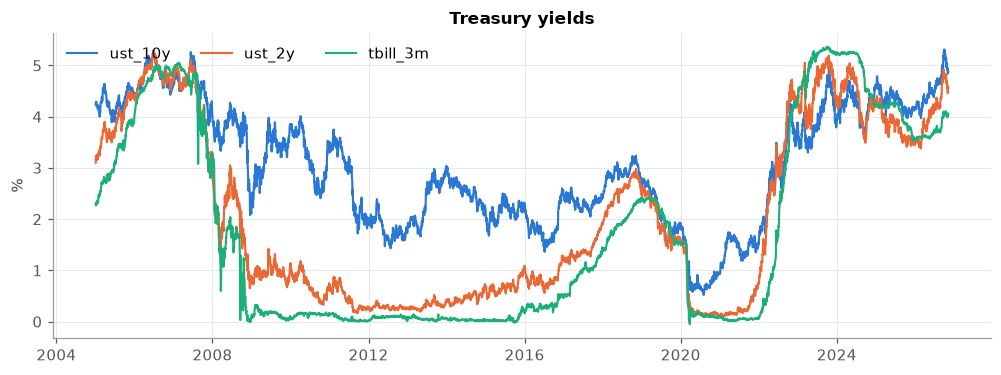

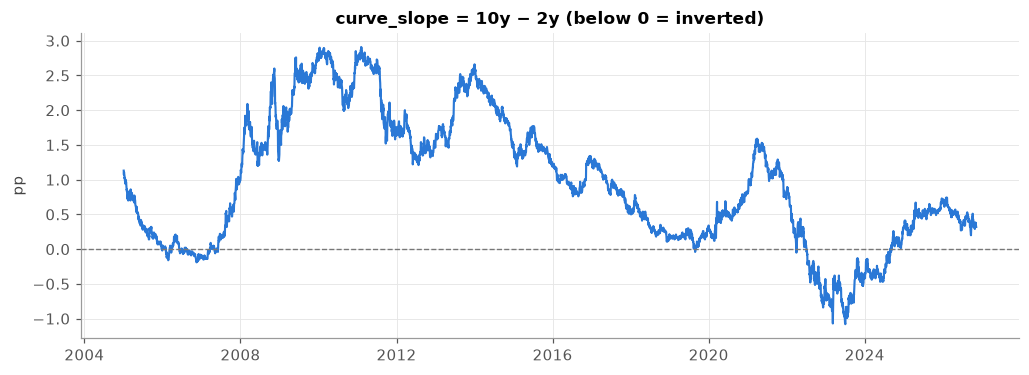

In [8]:
START = "2005-01-01"
rates = get_series(["ust_10y", "ust_2y", "tbill_3m"], start=START, as_of=TODAY)
lines(rates, "Treasury yields", "%"); plt.show()
lines(get_features("curve_slope", start=START, as_of=TODAY), "curve_slope = 10y − 2y (below 0 = inverted)", "pp", hline=0); plt.show()

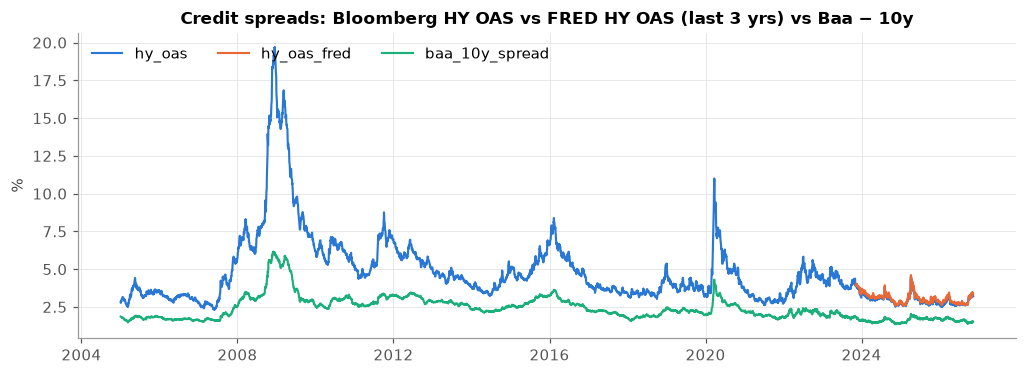

Bloomberg vs FRED HY OAS where both exist: 770 days, mean gap 0.10 pp, max 0.26 pp
[PASS] Bloomberg and FRED HY OAS roughly agree  (mean gap 0.10 pp (different index families))


In [9]:
credit = get_series(["hy_oas", "hy_oas_fred", "baa_10y_spread"], start=START, as_of=TODAY)
lines(credit, "Credit spreads: Bloomberg HY OAS vs FRED HY OAS (last 3 yrs) vs Baa − 10y", "%"); plt.show()
both = credit[["hy_oas", "hy_oas_fred"]].dropna()
gap = (both["hy_oas"] - both["hy_oas_fred"]).abs()
print(f"Bloomberg vs FRED HY OAS where both exist: {len(both)} days, mean gap {gap.mean():.2f} pp, max {gap.max():.2f} pp")
check(6, "Bloomberg and FRED HY OAS roughly agree", gap.mean() < 0.5, f"mean gap {gap.mean():.2f} pp (different index families)")

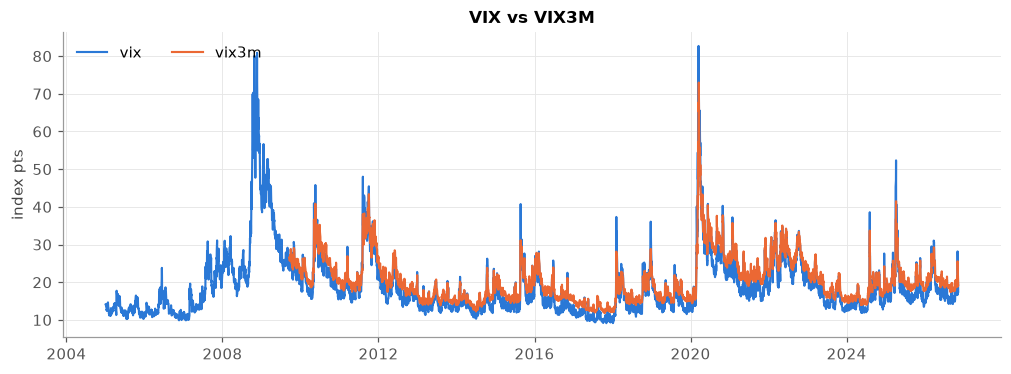

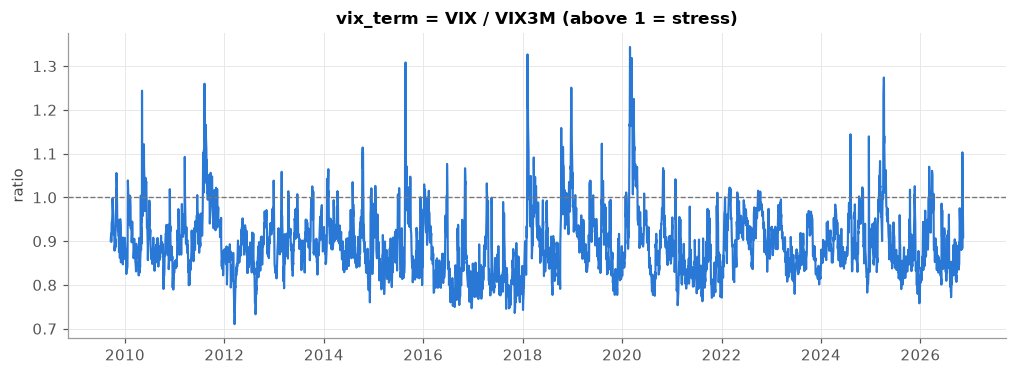

[PASS] VIX closed at 82.69 on 2020-03-16  (82.69)


In [10]:
vol = get_series(["vix", "vix3m"], start=START, as_of=TODAY)
lines(vol, "VIX vs VIX3M", "index pts"); plt.show()
lines(get_features("vix_term", start=START, as_of=TODAY), "vix_term = VIX / VIX3M (above 1 = stress)", "ratio", hline=1); plt.show()
m = get_series("vix", start="2020-03-16", end="2020-03-16", as_of=TODAY)["vix"].iloc[0]
check(6, "VIX closed at 82.69 on 2020-03-16", abs(m - 82.69) < 0.01, f"{m:.2f}")

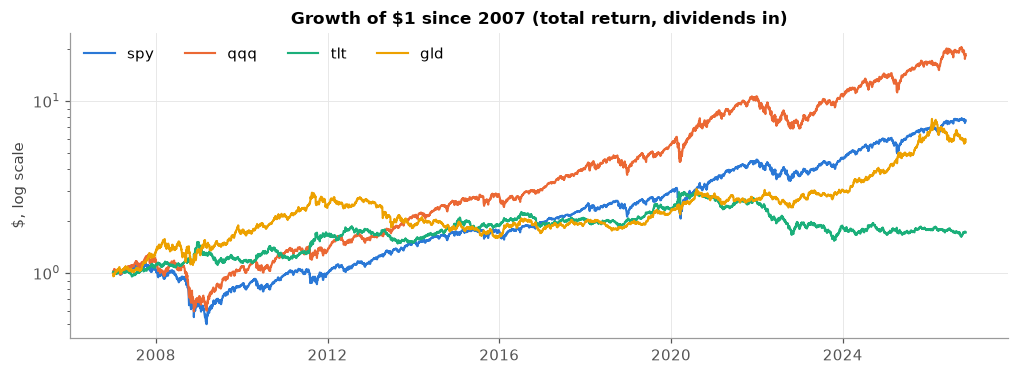

spy     7.70
qqq    18.69
tlt     1.71
gld     5.78


In [11]:
tr = get_prices(["spy", "qqq", "tlt", "gld"], start="2007-01-01", as_of=TODAY, field="total_return")
growth = (1 + tr.fillna(0)).cumprod()
lines(growth, "Growth of $1 since 2007 (total return, dividends in)", "$, log scale", logy=True); plt.show()
print((growth.iloc[-1]).round(2).to_string())

**Split and dividend handling.** `total_return` is built from as-traded prices + dividends + split ratios. It should match yfinance's adjusted close day by day. TQQQ has had several splits, so it's the hardest case.

[PASS] spy: total_return matches adj_close returns  (max daily gap 0.00025, worst day 2020-03-20)
[PASS] tqqq: total_return matches adj_close returns  (max daily gap 0.00037, worst day 2022-12-22)


,series_id,ex_date,split_ratio
0,qqq,2000-03-20,2.0
1,tqqq,2011-02-25,2.0
2,tqqq,2012-05-11,2.0
3,tqqq,2014-01-24,2.0
4,tqqq,2017-01-12,2.0
5,tqqq,2018-05-24,3.0
6,tqqq,2021-01-21,2.0
7,tqqq,2022-01-13,2.0
8,tqqq,2025-11-20,2.0


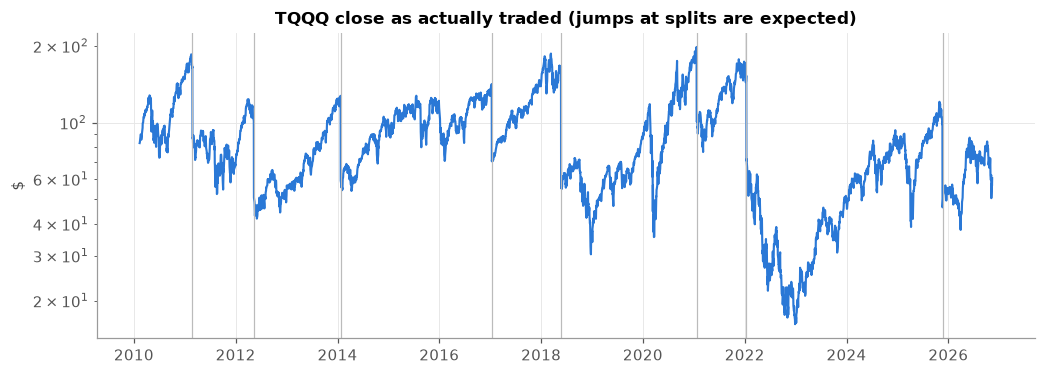

,series_id,ex_date,dividend
5,spy,2025-06-20,1.761
6,spy,2025-09-19,1.831
7,spy,2025-12-19,1.993
8,spy,2026-03-20,1.797
9,spy,2026-06-18,1.904
10,spy,2026-09-18,1.889


In [12]:
for sid in ["spy", "tqqq"]:
    t = get_prices(sid, start="2011-01-01", as_of=TODAY, field="total_return")[sid]
    adj = get_prices(sid, start="2011-01-01", as_of=TODAY, field="adj_close")[sid].pct_change()
    diff = (t - adj).abs().dropna()
    check(6, f"{sid}: total_return matches adj_close returns", diff.max() < 0.002,
          f"max daily gap {diff.max():.5f}, worst day {diff.idxmax().date()}")

splits = q("SELECT series_id, ex_date, split_ratio FROM raw.corporate_actions WHERE split_ratio > 0 ORDER BY 1, 2")
display(splits)
close = get_prices("tqqq", start="2010-01-01", as_of=TODAY, field="close")
ax = lines(close, "TQQQ close as actually traded (jumps at splits are expected)", "$", logy=True)
for d in splits.loc[splits.series_id == "tqqq", "ex_date"]:
    ax.axvline(pd.Timestamp(d), color="#bbb", lw=0.8)
plt.show()
display(get_dividends("spy", start="2024-01-01", as_of=TODAY).tail(6))

## 7. Options implied vol (Bloomberg)
Grid per underlying: 4 tenors (30, 60, 90, 180 days) × 5 strikes (90–110% of spot).

In [13]:
cov = q("""SELECT underlying, min(obs_date) AS first, max(obs_date) AS last, count(DISTINCT obs_date) AS days,
                  count(DISTINCT tenor_days) AS tenors, count(DISTINCT moneyness) AS strikes,
                  count(*) AS cells, round(100 * min(iv), 1) AS min_iv_pct, round(100 * max(iv), 1) AS max_iv_pct
           FROM raw.option_iv GROUP BY 1 ORDER BY 1""")
display(cov)
check(7, "IV grids loaded for spx, ndx, tlt, gld, tqqq", set(cov.underlying) == {"spx", "ndx", "tlt", "gld", "tqqq"})
check(7, "every grid has 4 tenors x 5 strikes", bool(((cov.tenors == 4) & (cov.strikes == 5)).all()))

,underlying,first,last,days,tenors,strikes,cells,min_iv_pct,max_iv_pct
0,gld,2008-06-04,2026-11-10,4638,4,5,92760,7.9,69.8
1,ndx,2005-01-03,2026-11-10,5499,4,5,109979,1.7,82.0
2,spx,2005-01-03,2026-11-10,5499,4,5,109980,6.3,85.7
3,tlt,2005-01-03,2026-11-10,5499,4,5,109980,6.2,57.9
4,tqqq,2010-03-01,2026-11-10,4201,4,5,82495,22.9,234.4


[PASS] IV grids loaded for spx, ndx, tlt, gld, tqqq
[PASS] every grid has 4 tenors x 5 strikes


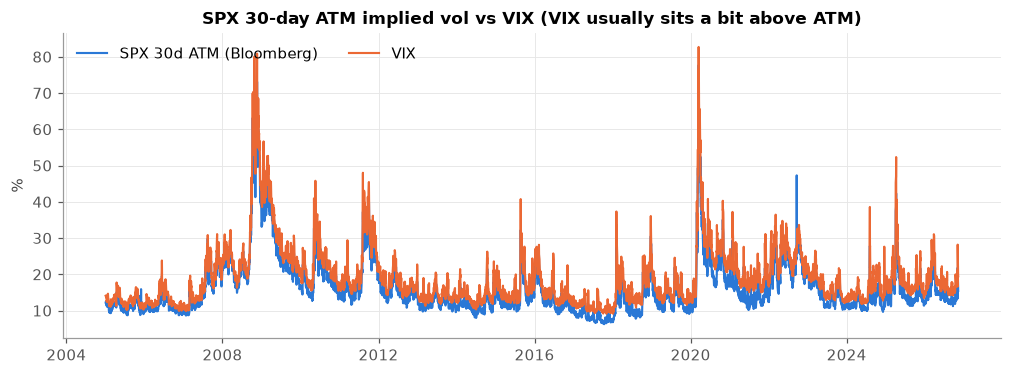

[PASS] SPX 30d ATM tracks VIX  (correlation 0.991)


In [14]:
iv = get_option_iv("spx", start=START, as_of=TODAY, tenor_days=[30], moneyness_type="pct_spot")
atm = iv[iv.moneyness == 100].set_index("obs_date")["iv"].mul(100).rename("SPX 30d ATM (Bloomberg)")
atm.index = pd.to_datetime(atm.index)
cmp = pd.concat([atm, get_series("vix", start=START, as_of=TODAY)["vix"].rename("VIX")], axis=1, sort=True).dropna()
lines(cmp, "SPX 30-day ATM implied vol vs VIX (VIX usually sits a bit above ATM)", "%"); plt.show()
corr = cmp.corr().iloc[0, 1]
check(7, "SPX 30d ATM tracks VIX", corr > 0.95, f"correlation {corr:.3f}")

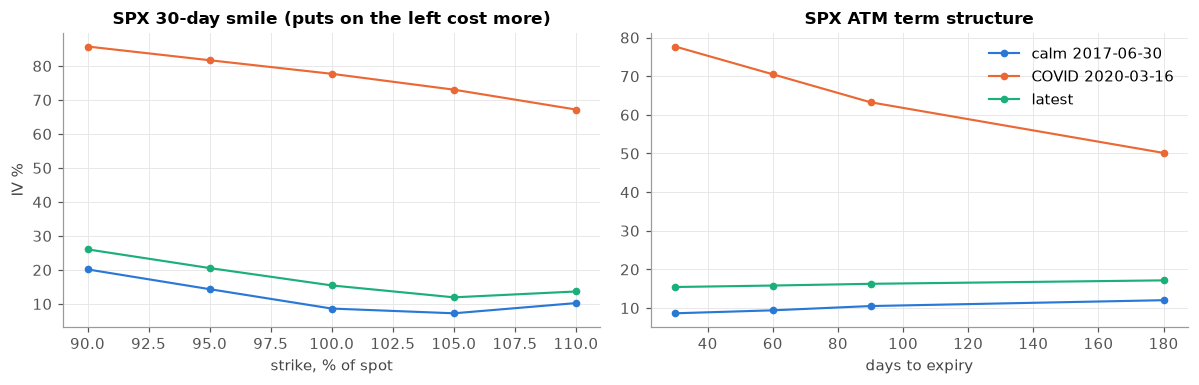

In [15]:
days = {"calm 2017-06-30": "2017-06-30", "COVID 2020-03-16": "2020-03-16", "latest": None}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (label, d) in enumerate(days.items()):
    d = d or str(q("SELECT max(obs_date) d FROM raw.option_iv WHERE underlying = 'spx'")["d"][0])
    g = get_option_iv("spx", start=d, end=d, as_of=TODAY)
    s = g[g.tenor_days == 30].sort_values("moneyness")
    axes[0].plot(s.moneyness, s.iv * 100, marker="o", ms=4, color=COLORS[i], label=label)
    t = g[g.moneyness == 100].sort_values("tenor_days")
    axes[1].plot(t.tenor_days, t.iv * 100, marker="o", ms=4, color=COLORS[i], label=label)
axes[0].set_title("SPX 30-day smile (puts on the left cost more)"); axes[0].set_xlabel("strike, % of spot"); axes[0].set_ylabel("IV %")
axes[1].set_title("SPX ATM term structure"); axes[1].set_xlabel("days to expiry"); axes[1].legend()
plt.tight_layout(); plt.show()

**Glitch scan.** A real market move shifts the whole surface and lasts. A data glitch breaks from **both** the days either side **and** its neighbours on the same day's surface. A cell is flagged only when all of these hold:
- it is more than 35% away from the previous day **and** the next day, in the same direction, and
- it is more than 35% away from the average of its neighbouring strikes that day.

In [16]:
raw_iv = q("SELECT underlying, obs_date, tenor_days, moneyness, iv FROM raw.option_iv")
flags = []
for (u, t), g in raw_iv.groupby(["underlying", "tenor_days"]):
    w = g.pivot(index="obs_date", columns="moneyness", values="iv").sort_index()
    prev, nxt = w.shift(1), w.shift(-1)
    time_jump = ((w / prev - 1).abs() > 0.35) & ((w / nxt - 1).abs() > 0.35) & (np.sign(w - prev) == np.sign(w - nxt))
    nb = (w.shift(1, axis=1) + w.shift(-1, axis=1)) / 2
    nb = nb.fillna(w.shift(1, axis=1)).fillna(w.shift(-1, axis=1))
    strike_jump = (w / nb - 1).abs() > 0.35
    row_jump = time_jump.sum(axis=1) >= 3           # whole row jumped at once (e.g. SPX 2022-09-20)
    bad = time_jump & (strike_jump | row_jump.values[:, None])
    for d, m in bad.stack()[lambda s: s].index:
        flags.append({"underlying": u, "obs_date": d, "tenor_days": t, "moneyness": m,
                      "prev_pct": round(prev.loc[d, m] * 100, 1), "value_pct": round(w.loc[d, m] * 100, 1),
                      "next_pct": round(nxt.loc[d, m] * 100, 1)})
flags = pd.DataFrame(flags)
if len(flags):
    flags["obs_date"] = pd.to_datetime(flags["obs_date"]).dt.date
    by_day = (flags.groupby(["underlying", "obs_date"])
                   .agg(cells=("iv", "size") if "iv" in flags else ("value_pct", "size"),
                        tenors=("tenor_days", lambda s: sorted(set(s))),
                        prev_pct=("prev_pct", "median"), value_pct=("value_pct", "median"), next_pct=("next_pct", "median"))
                   .reset_index())
    print("Flagged cells grouped by day (median values). Identical values across strikes = a flat, failed surface.")
    display(by_day)
    print("Every flagged cell: run `flags` in a new cell.")
else:
    display(Markdown("No glitches found."))
known = {("ndx", "2005-10-20"), ("tlt", "2008-12-01"), ("spx", "2022-09-20"), ("tlt", "2026-03-16")}
found = {(r.underlying, str(r.obs_date)) for r in flags.itertuples()} if len(flags) else set()
check(7, "IV glitch scan", "WARN" if len(flags) else True,
      f"{len(flags)} cells on {len(found)} dates flagged; kept in raw, to be filtered in the clean layer")
check(7, "the 4 known glitch dates are caught", known <= found, ", ".join(sorted(f"{u} {d}" for u, d in known - found)) or "")

Flagged cells grouped by day (median values). Identical values across strikes = a flat, failed surface.


,underlying,obs_date,cells,tenors,prev_pct,value_pct,next_pct
0,ndx,2005-10-20,4,[90],15.95,1.80,16.10
1,ndx,2008-12-23,15,"[30, 60, 90]",29.20,42.70,29.50
2,ndx,2009-05-22,12,"[30, 60, 90, 180]",21.30,30.20,20.80
3,ndx,2009-06-23,12,"[30, 60, 90, 180]",21.50,30.30,20.60
4,ndx,2014-06-25,1,[180],16.00,21.80,15.80
5,ndx,2015-03-26,2,"[60, 90]",19.55,29.15,19.25
6,ndx,2015-07-31,1,[90],17.20,24.70,17.70
7,spx,2005-11-30,3,[30],9.90,15.00,9.60
8,spx,2006-10-18,1,[30],9.10,12.60,9.20
9,spx,2006-12-01,1,[30],7.70,11.60,8.30


Every flagged cell: run `flags` in a new cell.
[WARN] IV glitch scan  (107 cells on 29 dates flagged; kept in raw, to be filtered in the clean layer)
[PASS] the 4 known glitch dates are caught


## 8. Features
All 15 model inputs. Shaded bands: 2008 crisis, March 2020, 2022 rate shock.

,feature_id,description,inputs,units
0,credit_spread,"High-yield OAS: Bloomberg full history, FRED c...","hy_oas, hy_oas_fred",percent
1,credit_spread_chg_20d,20-day change in credit_spread,"hy_oas, hy_oas_fred",percentage points
2,curve_slope,10y minus 2y Treasury yield,"ust_10y, ust_2y",percentage points
3,log_vix,Natural log of VIX,vix,log index points
4,rv_qqq_1d,"1-day realised vol of QQQ, annualised (HAR input)",qqq,annualised decimal
5,rv_qqq_22d,"22-day realised vol of QQQ, annualised (HAR in...",qqq,annualised decimal
6,rv_qqq_5d,"5-day realised vol of QQQ, annualised (HAR input)",qqq,annualised decimal
7,rv_spy_1d,"1-day realised vol of SPY, annualised (HAR input)",spy,annualised decimal
8,rv_spy_22d,"22-day realised vol of SPY, annualised (HAR in...",spy,annualised decimal
9,rv_spy_5d,"5-day realised vol of SPY, annualised (HAR input)",spy,annualised decimal


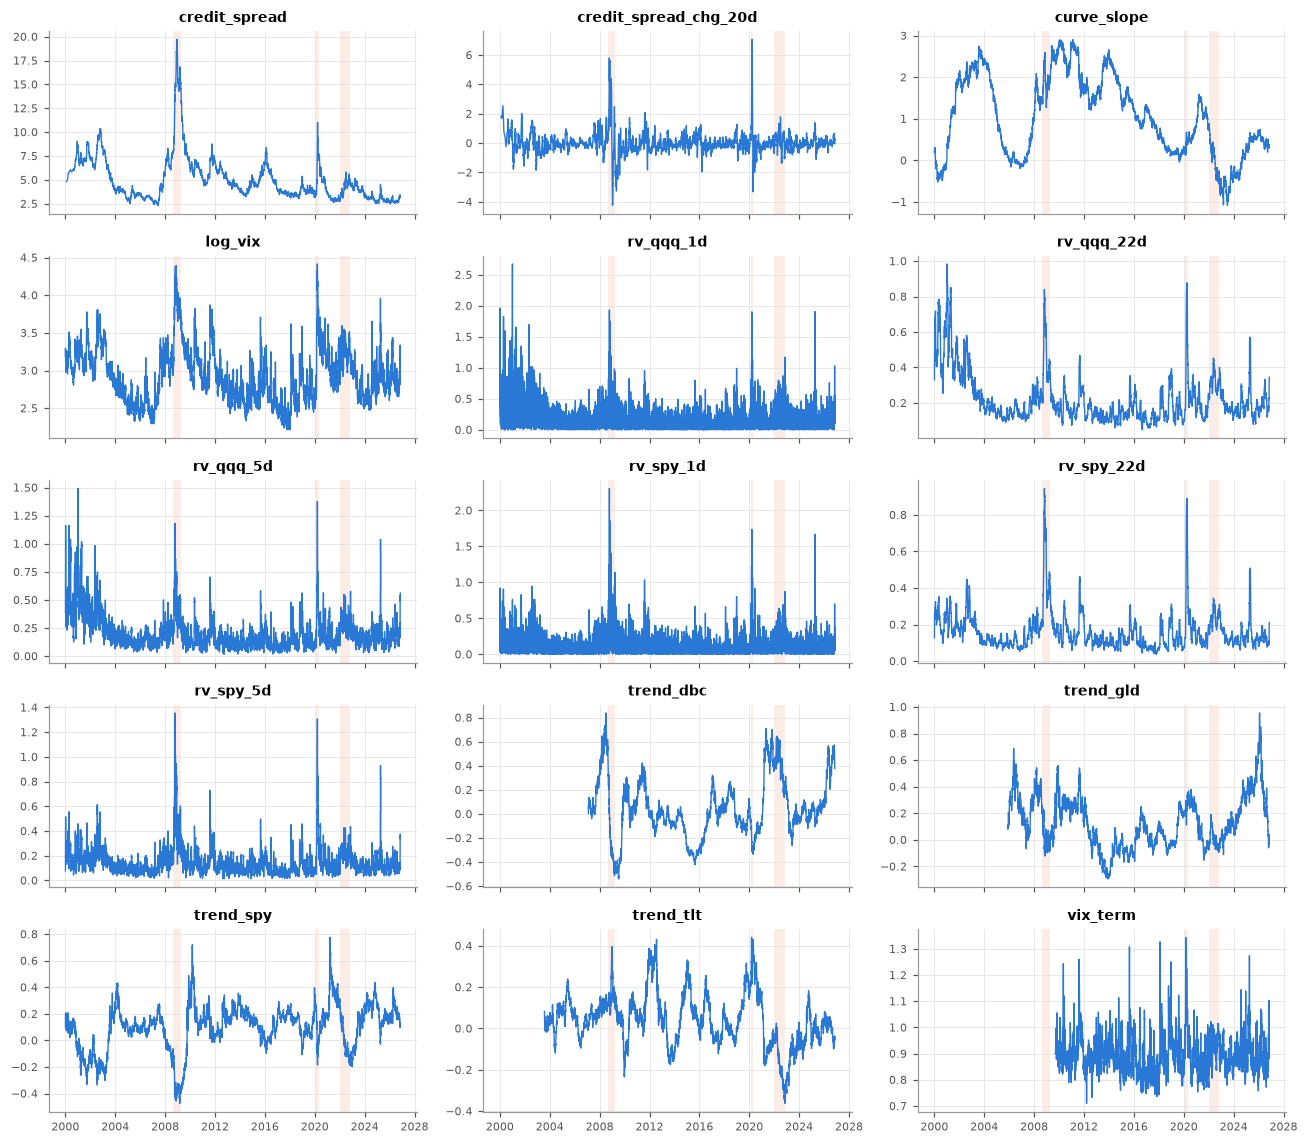

,count,mean,min,max,first
credit_spread,6612.0,4.983,2.330,19.710,2000-01-31
credit_spread_chg_20d,6612.0,-0.004,-4.240,7.060,2000-01-31
curve_slope,6717.0,1.043,-1.080,2.910,2000-01-03
log_vix,6790.0,2.917,2.213,4.415,2000-01-03
rv_qqq_1d,6756.0,0.179,0.000,2.674,2000-01-03
rv_qqq_22d,6756.0,0.226,0.048,0.984,2000-01-03
rv_qqq_5d,6756.0,0.216,0.017,1.492,2000-01-03
rv_spy_1d,6756.0,0.127,0.000,2.305,2000-01-03
rv_spy_22d,6756.0,0.162,0.037,0.945,2000-01-03
rv_spy_5d,6756.0,0.154,0.013,1.356,2000-01-03


[WARN] first date with all core regime inputs  (2009-09-18 (vix_term needs VIX3M))


In [17]:
feats = list_features()
display(feats[["feature_id", "description", "inputs", "units"]])
F = get_features(feats.feature_id.tolist(), start="2000-01-01", as_of=TODAY)
n = len(F.columns); cols = 3; rows = -(-n // cols)
fig, axes = plt.subplots(rows, cols, figsize=(12, 2.1 * rows), sharex=True)
for ax, c in zip(axes.flat, F.columns):
    s = F[c].dropna()
    ax.plot(s.index, s.values, color=COLORS[0], lw=0.9)
    for a, b in [("2008-09-01", "2009-03-31"), ("2020-02-20", "2020-04-30"), ("2022-01-01", "2022-10-31")]:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#eb6834", alpha=0.12, lw=0)
    ax.set_title(c, fontsize=9); ax.tick_params(labelsize=7)
for ax in list(axes.flat)[n:]:
    ax.set_visible(False)
plt.tight_layout(); plt.show()

stats = F.describe().T[["count", "mean", "min", "max"]]
stats["first"] = [F[c].first_valid_index().date() for c in F.columns]
display(stats.round(3))
regime_start = max(F[c].first_valid_index() for c in ["curve_slope", "credit_spread", "log_vix", "vix_term", "trend_spy"])
check(8, "first date with all core regime inputs", "WARN" if regime_start > pd.Timestamp("2008-01-01") else True,
      f"{regime_start.date()} (vix_term needs VIX3M)")

## 9. Summary

In [18]:
res = pd.DataFrame(RESULTS)
counts = res["result"].value_counts().reindex(["PASS", "WARN", "FAIL"], fill_value=0)
print(f"PASS {counts['PASS']}   WARN {counts['WARN']}   FAIL {counts['FAIL']}")
order = {"FAIL": 0, "WARN": 1, "PASS": 2}
display(res.sort_values(["result", "section"], key=lambda c: c.map(order) if c.name == "result" else c)
           .reset_index(drop=True))

PASS 39   WARN 6   FAIL 0


,section,check,result,detail
0,3,CBOE vol indices start before 2008,WARN,"start 2009+: ['gvz', 'ovx', 'vix3m', 'vix9d', ..."
1,4,no weekend dates,WARN,weekend rows: hy_oas_fred (11) (FRED's HY OAS ...
2,4,implied vols in a sane range (2% to 300%),WARN,"4 values outside (known Bloomberg glitches, se..."
3,4,features have one version per date,WARN,extra versions: credit_spread_chg_20d (238)
4,7,IV glitch scan,WARN,"107 cells on 29 dates flagged; kept in raw, to..."
5,8,first date with all core regime inputs,WARN,2009-09-18 (vix_term needs VIX3M)
6,1,market_data.duckdb exists,PASS,
7,1,schema version recorded,PASS,
8,1,core tables have rows,PASS,
9,1,market_data.duckdb exists,PASS,


In [19]:
# Release the read-only connection so refresh.py can write. Run this before refreshing.
access.close()
print("Connection closed.")

Connection closed.
